<a href="https://colab.research.google.com/github/clobos/Biologia_2026/blob/main/Teste_hipoteses_Biologia.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aula 1

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# Configurações gerais para as curvas
mu0, mu1 = 0, 2.8
sigma = 1
x = np.linspace(-4, 6, 1000)
y0 = norm.pdf(x, mu0, sigma)
y1 = norm.pdf(x, mu1, sigma)
alpha = 0.05
x_crit = norm.ppf(1 - alpha, mu0, sigma)
x_crit


np.float64(1.6448536269514722)

## DISTRIBUIÇÃO DA ESTATÍSTICA SOB H0 E SOB H1

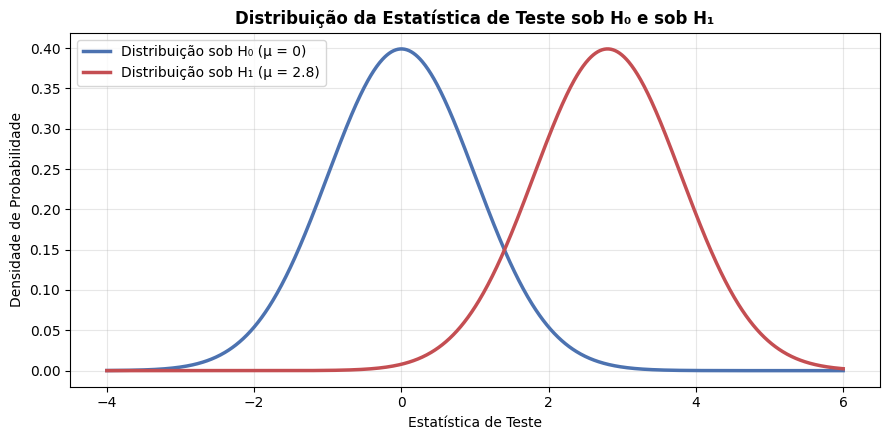

In [ ]:
fig1, ax1 = plt.subplots(figsize=(9, 4.5))
ax1.plot(x, y0, color="#4C72B0", lw=2.5, label="Distribuição sob H₀ (μ = 0)")
ax1.plot(x, y1, color="#C44E52", lw=2.5, label="Distribuição sob H₁ (μ = 2.8)")
ax1.set_title("Distribuição da Estatística de Teste sob H₀ e sob H₁", fontsize=12, fontweight='bold')
ax1.set_xlabel("Estatística de Teste")
ax1.set_ylabel("Densidade de Probabilidade")
ax1.legend()
ax1.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

##  NÍVEL DE SIGNIFICÂNCIA ($\alpha$)

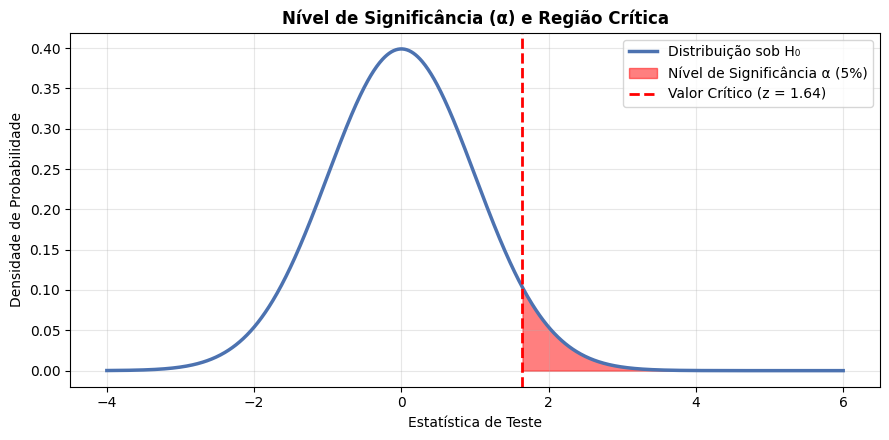

In [ ]:
fig2, ax2 = plt.subplots(figsize=(9, 4.5))
ax2.plot(x, y0, color="#4C72B0", lw=2.5, label="Distribuição sob H₀")
# Preencher a região crítica (Alpha)
x_alpha = np.linspace(x_crit, 6, 500)
y_alpha = norm.pdf(x_alpha, mu0, sigma)
ax2.fill_between(x_alpha, y_alpha, color="red", alpha=0.5, label=f"Nível de Significância α ({alpha*100:.0f}%)")
ax2.axvline(x_crit, color="red", ls="--", lw=2, label=f"Valor Crítico (z = {x_crit:.2f})")
ax2.set_title("Nível de Significância (α) e Região Crítica", fontsize=12, fontweight='bold')
ax2.set_xlabel("Estatística de Teste")
ax2.set_ylabel("Densidade de Probabilidade")
ax2.legend()
ax2.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



## ERRO TIPO I e ERRO TIPO II

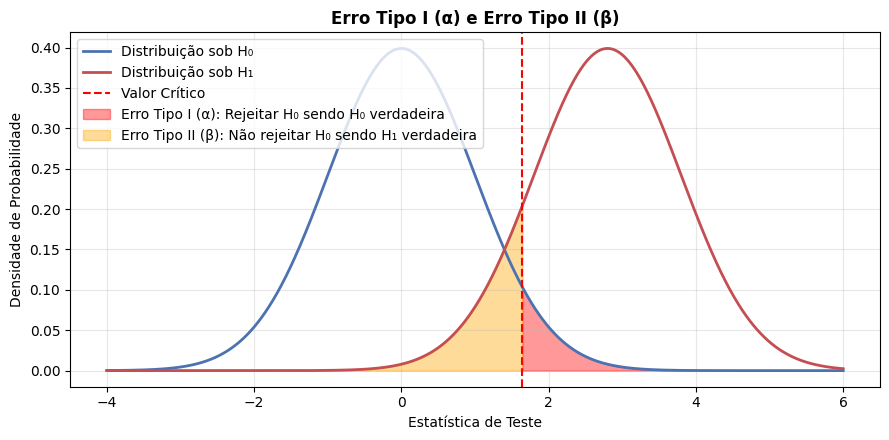

In [ ]:
fig3, ax3 = plt.subplots(figsize=(9, 4.5))
ax3.plot(x, y0, color="#4C72B0", lw=2, label="Distribuição sob H₀")
ax3.plot(x, y1, color="#C44E52", lw=2, label="Distribuição sob H₁")
ax3.axvline(x_crit, color="red", ls="--", lw=1.5, label="Valor Crítico")

# Erro Tipo I (área vermelha sob H0 à direita do valor crítico)
x_err1 = np.linspace(x_crit, 6, 500)
y_err1 = norm.pdf(x_err1, mu0, sigma)
ax3.fill_between(x_err1, y_err1, color="red", alpha=0.4, label="Erro Tipo I (α): Rejeitar H₀ sendo H₀ verdadeira")

# Erro Tipo II (área amarela sob H1 à esquerda do valor crítico)
x_err2 = np.linspace(-4, x_crit, 500)
y_err2 = norm.pdf(x_err2, mu1, sigma)
ax3.fill_between(x_err2, y_err2, color="orange", alpha=0.4, label="Erro Tipo II (β): Não rejeitar H₀ sendo H₁ verdadeira")

ax3.set_title("Erro Tipo I (α) e Erro Tipo II (β)", fontsize=12, fontweight='bold')
ax3.set_xlabel("Estatística de Teste")
ax3.set_ylabel("Densidade de Probabilidade")
ax3.legend(loc="upper left")
ax3.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



## PODER DO TESTE (1 - $\beta$)

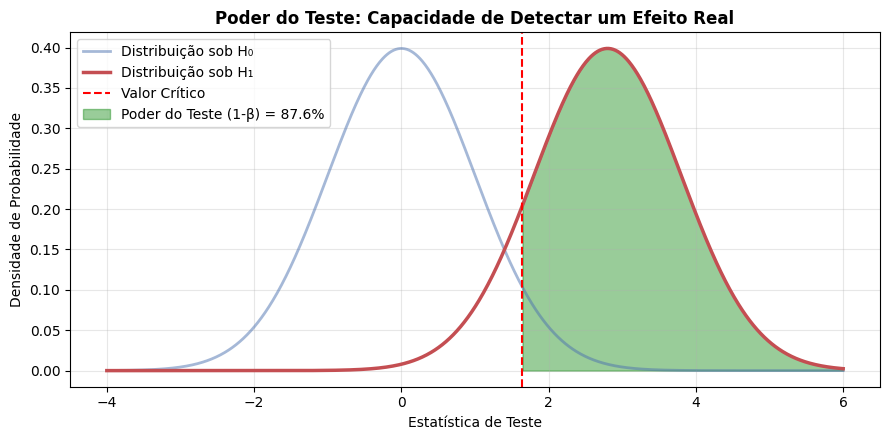

In [ ]:
fig4, ax4 = plt.subplots(figsize=(9, 4.5))
ax4.plot(x, y0, color="#4C72B0", lw=2, alpha=0.5, label="Distribuição sob H₀")
ax4.plot(x, y1, color="#C44E52", lw=2.5, label="Distribuição sob H₁")
ax4.axvline(x_crit, color="red", ls="--", lw=1.5, label="Valor Crítico")

# Poder do teste (área verde sob H1 à direita do valor crítico)
x_power = np.linspace(x_crit, 6, 500)
y_power = norm.pdf(x_power, mu1, sigma)
power_val = 1 - norm.cdf(x_crit, mu1, sigma)
ax4.fill_between(x_power, y_power, color="green", alpha=0.4, label=f"Poder do Teste (1-β) = {power_val*100:.1f}%")

ax4.set_title("Poder do Teste: Capacidade de Detectar um Efeito Real", fontsize=12, fontweight='bold')
ax4.set_xlabel("Estatística de Teste")
ax4.set_ylabel("Densidade de Probabilidade")
ax4.legend(loc="upper left")
ax4.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



## CONCEITO DE P-VALOR

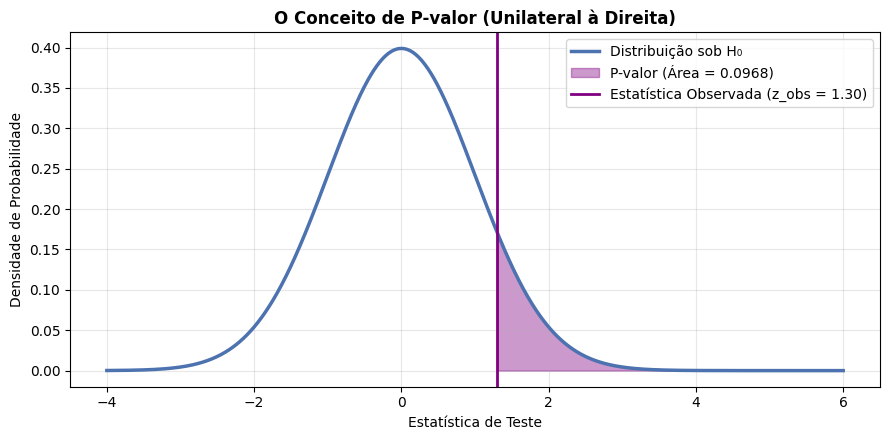

In [ ]:
fig5, ax5 = plt.subplots(figsize=(9, 4.5))
ax5.plot(x, y0, color="#4C72B0", lw=2.5, label="Distribuição sob H₀")

# Simular uma estatística observada
z_obs = 1.3
y_obs = norm.pdf(z_obs, mu0, sigma)
p_value = 1 - norm.cdf(z_obs, mu0, sigma)

# Área do p-valor (à direita do valor observado)
x_p = np.linspace(z_obs, 6, 500)
y_p = norm.pdf(x_p, mu0, sigma)
ax5.fill_between(x_p, y_p, color="purple", alpha=0.4, label=f"P-valor (Área = {p_value:.4f})")
ax5.axvline(z_obs, color="purple", ls="-", lw=2, label=f"Estatística Observada (z_obs = {z_obs:.2f})")

ax5.set_title("O Conceito de P-valor (Unilateral à Direita)", fontsize=12, fontweight='bold')
ax5.set_xlabel("Estatística de Teste")
ax5.set_ylabel("Densidade de Probabilidade")
ax5.legend()
ax5.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Introdução

In [ ]:
import pandas as pd, numpy as np
from scipy import stats

url = ("https://raw.githubusercontent.com/"
 "allisonhorst/palmerpenguins/main/"
 "inst/extdata/penguins.csv")
df = pd.read_csv(url)

# Filtrar Adelie + Torgersen
mask = ((df["species"] == "Adelie") &
 (df["island"] == "Torgersen"))
massa = df.loc[mask, "body_mass_g"].dropna()

n = len(massa)
xb = massa.mean()
s = massa.std(ddof=1)
se = s / np.sqrt(n)
mu0 = 3700
t_obs = (xb - mu0) / se

print(f"n={n}, x̄={xb:.1f}, s={s:.1f}")
print(f"SE={se:.2f}, t_obs={t_obs:.4f}")

n=51, x̄=3706.4, s=445.1
SE=62.33, t_obs=0.1022


In [ ]:
from scipy.stats import t as t_dist

# Graus de liberdade
gl = n - 1

# valor-p bilateral manual
p_manual = 2 * t_dist.sf(abs(t_obs), df=gl)

# Verificação com scipy
t_stat, p_scipy = stats.ttest_1samp(
    massa, popmean=mu0)

print(f"t_obs (manual) = {t_obs:.4f}")
print(f"p (manual)     = {p_manual:.4f}")
print(f"t (scipy)      = {t_stat:.4f}")
print(f"p (scipy)      = {p_scipy:.4f}")

t_obs (manual) = 0.1022
p (manual)     = 0.9190
t (scipy)      = 0.1022
p (scipy)      = 0.9190


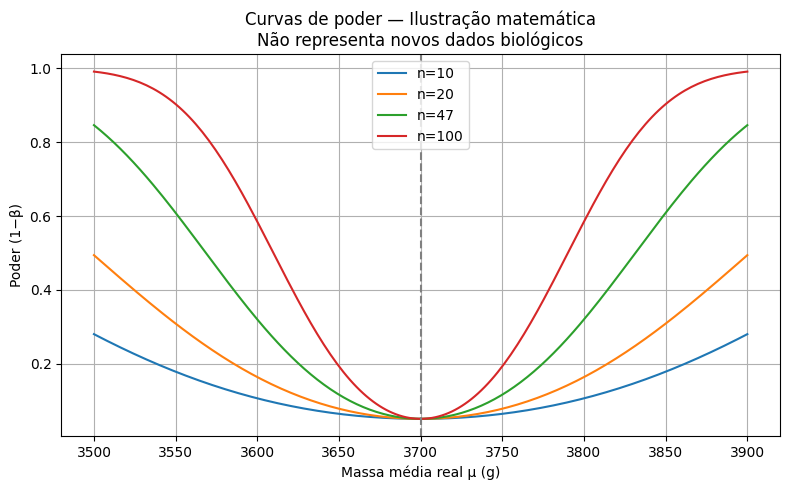

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# Ilustração com variância conhecida (sigma fixo)
# Rotulo: ilustração matemática
sigma = 460  # valor aproximado dos dados
alpha = 0.05
mu0   = 3700
ns    = [10, 20, 47, 100]
mus   = np.linspace(3500, 3900, 200)

fig, ax = plt.subplots(figsize=(8, 5))
for n in ns:
    se  = sigma / np.sqrt(n)
    zc  = norm.ppf(1 - alpha/2)
    # Poder bilateral
    pow_vals = (norm.cdf(-zc - (mus-mu0)/se)
              + norm.sf( zc - (mus-mu0)/se))
    ax.plot(mus, pow_vals, label=f"n={n}")

ax.axvline(mu0, ls="--", color="gray")
ax.set_xlabel("Massa média real μ (g)")
ax.set_ylabel("Poder (1−β)")
ax.legend(); ax.grid(True)
ax.set_title(
  "Curvas de poder — Ilustração matemática\n"
  "Não representa novos dados biológicos")
plt.tight_layout(); plt.show()

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import t as t_dist

# ----------------------------------------------------------
# 1. Leitura e filtragem dos dados
# ----------------------------------------------------------
url = ("https://raw.githubusercontent.com/"
 "allisonhorst/palmerpenguins/main/"
 "inst/extdata/penguins.csv")
df = pd.read_csv(url)

mask = ((df["species"] == "Adelie") &
 (df["island"] == "Torgersen"))
massa = df.loc[mask, "body_mass_g"].dropna()
print(f"N amostral: {len(massa)}")
print(massa.describe())



N amostral: 51
count      51.000000
mean     3706.372549
std       445.107940
min      2900.000000
25%      3337.500000
50%      3700.000000
75%      4000.000000
max      4700.000000
Name: body_mass_g, dtype: float64


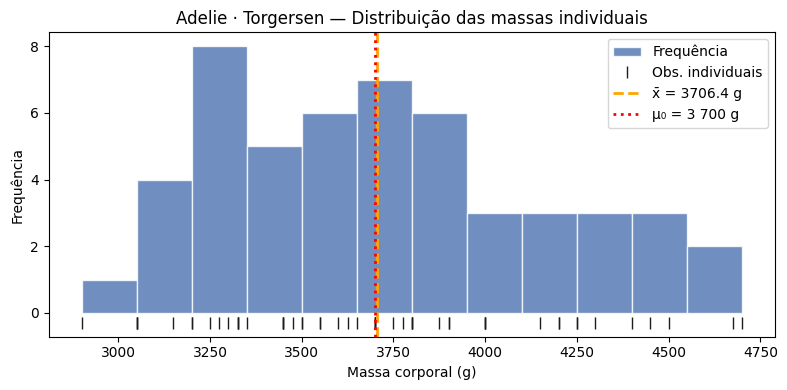

In [ ]:
# ----------------------------------------------------------
# 2. Histograma com pontos individuais (stripplot)
# ----------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(massa, bins=12, color="#4C72B0",
 edgecolor="white", alpha=0.8,
 label="Frequência")
ax.plot(massa,
 np.full(len(massa), -0.3),
 "|", color="#1D1D1B",
 markersize=8, label="Obs. individuais")
ax.axvline(massa.mean(), color="orange",
 lw=2, ls="--", label=f"x̄ = {massa.mean():.1f} g")
ax.axvline(3700, color="red",
 lw=2, ls=":", label="μ₀ = 3 700 g")
ax.set_xlabel("Massa corporal (g)")
ax.set_ylabel("Frequência")
ax.set_title("Adelie · Torgersen — Distribuição das massas individuais")
ax.legend(); plt.tight_layout(); plt.show()



In [ ]:
# ----------------------------------------------------------
# 3. Cálculo manual da estatística T e valor-p
# ----------------------------------------------------------
mu0 = 3700
n = len(massa)
xb = massa.mean()
s = massa.std(ddof=1)
se = s / np.sqrt(n)
gl = n - 1
t_obs = (xb - mu0) / se
p_bilateral = 2 * t_dist.sf(abs(t_obs), df=gl)

print(f"\nn = {n}")
print(f"x̄ = {xb:.2f} g")
print(f"s = {s:.2f} g")
print(f"SE = {se:.4f} g")
print(f"t = {t_obs:.4f}")
print(f"g.l.= {gl}")
print(f"p = {p_bilateral:.4f}")




n = 51
x̄ = 3706.37 g
s = 445.11 g
SE = 62.3276 g
t = 0.1022
g.l.= 50
p = 0.9190


In [ ]:
# ----------------------------------------------------------
# 4. Verificação com scipy.stats.ttest_1samp
# ----------------------------------------------------------
t_sc, p_sc = stats.ttest_1samp(massa, popmean=mu0)
print(f"\n[scipy] t = {t_sc:.4f}, p = {p_sc:.4f}")




[scipy] t = 0.1022, p = 0.9190


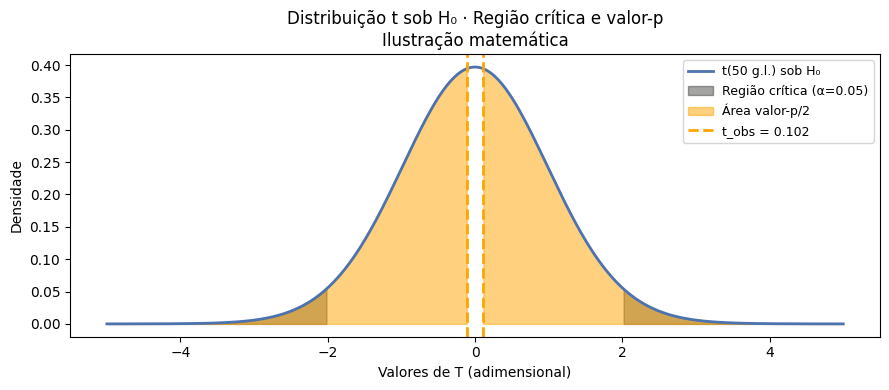

In [ ]:
# ----------------------------------------------------------
# 5. Curva t sob H₀ com região crítica e valor-p
# ----------------------------------------------------------
alpha = 0.05
x_vals = np.linspace(-5, 5, 400)
y_vals = t_dist.pdf(x_vals, df=gl)
t_crit = t_dist.ppf(1 - alpha/2, df=gl)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(x_vals, y_vals, color="#4C72B0",
 lw=2, label=f"t({gl} g.l.) sob H₀")

# Regiões críticas (α)
ax.fill_between(x_vals, y_vals,
 where=(x_vals >= t_crit), color="#1D1D1B",
 alpha=0.4, label=f"Região crítica (α={alpha})")
ax.fill_between(x_vals, y_vals,
 where=(x_vals <= -t_crit), color="#1D1D1B",
 alpha=0.4)

# Área do valor-p
ax.fill_between(x_vals, y_vals,
 where=(x_vals >= abs(t_obs)), color="orange",
 alpha=0.5, label=f"Área valor-p/2")
ax.fill_between(x_vals, y_vals,
 where=(x_vals <= -abs(t_obs)), color="orange",
 alpha=0.5)

ax.axvline(t_obs, color="orange", lw=2,
 ls="--", label=f"t_obs = {t_obs:.3f}")
ax.axvline(-t_obs, color="orange", lw=2, ls="--")

ax.set_xlabel("Valores de T (adimensional)")
ax.set_ylabel("Densidade")
ax.set_title(
 "Distribuição t sob H₀ · Região crítica e valor-p\n"
 "Ilustração matemática")
ax.legend(fontsize=9); plt.tight_layout(); plt.show()



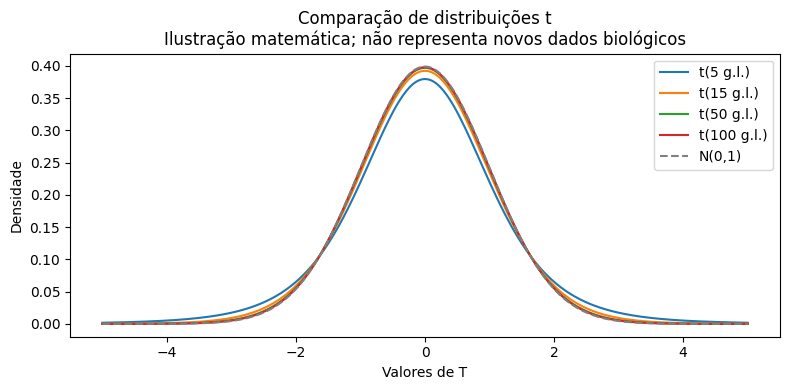

In [ ]:
# ----------------------------------------------------------
# 6. Comparação de distribuições t (diferentes g.l.)
# ----------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 4))
gls_comp = [5, 15, gl, 100]
for g in gls_comp:
 y = t_dist.pdf(x_vals, df=g)
 ax.plot(x_vals, y, label=f"t({g} g.l.)")
from scipy.stats import norm
ax.plot(x_vals, norm.pdf(x_vals),
 ls="--", color="gray", label="N(0,1)")
ax.set_xlabel("Valores de T"); ax.set_ylabel("Densidade")
ax.set_title(
 "Comparação de distribuições t\n"
 "Ilustração matemática; não representa novos dados biológicos")
ax.legend(); plt.tight_layout(); plt.show()



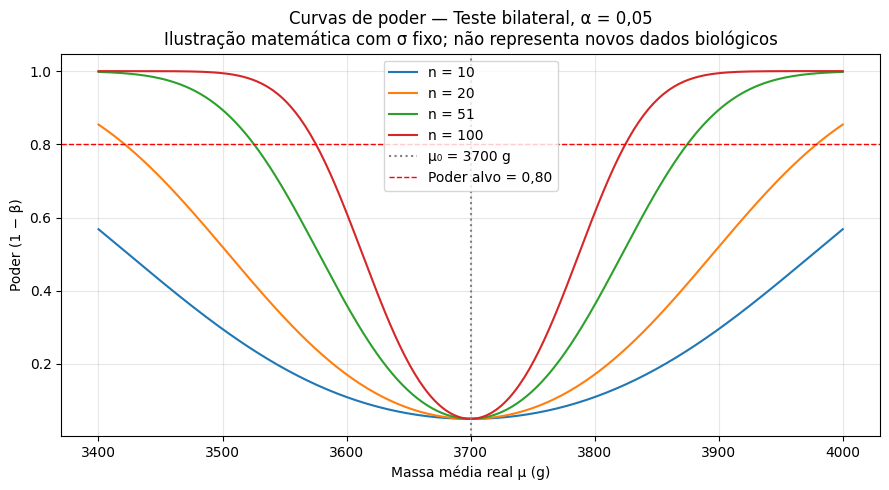

In [ ]:
# ----------------------------------------------------------
# 7. Curvas de poder (variância conhecida — ilustração)
# ----------------------------------------------------------
from scipy.stats import norm

sigma_est = s # usando s como estimativa de σ
ns_poder = [10, 20, n, 100]
mus_range = np.linspace(3400, 4000, 300)
alpha_p = 0.05

fig, ax = plt.subplots(figsize=(9, 5))
for n_k in ns_poder:
 se_k = sigma_est / np.sqrt(n_k)
 z_c = norm.ppf(1 - alpha_p/2)
 poder = (norm.cdf(-z_c - (mus_range-mu0)/se_k)
 + norm.sf( z_c - (mus_range-mu0)/se_k))
 ax.plot(mus_range, poder, label=f"n = {n_k}")

ax.axvline(mu0, ls=":", color="gray", label="μ₀ = 3700 g")
ax.axhline(0.80, ls="--", color="red",
 lw=1, label="Poder alvo = 0,80")
ax.set_xlabel("Massa média real μ (g)")
ax.set_ylabel("Poder (1 − β)")
ax.set_title(
 "Curvas de poder — Teste bilateral, α = 0,05\n"
 "Ilustração matemática com σ fixo; não representa novos dados biológicos")
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()



In [ ]:
#!pip install statsmodels

In [ ]:
# ----------------------------------------------------------
# Extensão opcional: poder do teste t via statsmodels
# ----------------------------------------------------------
from statsmodels.stats.power import TTestPower

# Redefinindo de forma segura as variáveis para evitar conflitos com células anteriores
n_atual = len(massa)
s_atual = massa.std(ddof=1)
efeito_d = 100 / s_atual # diferença de 100 g em unidades de s

# Inicializando o objeto de poder para teste T
power_analysis = TTestPower()
poder_t = power_analysis.solve_power(
    effect_size=efeito_d,
    nobs=n_atual,
    alpha=0.05,
    alternative="two-sided"
)

print(f"\n[statsmodels] Poder para Δ=100g, n={n_atual}: {poder_t:.3f}")


[statsmodels] Poder para Δ=100g, n=51: 0.350
